# Imports

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import glob
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams['figure.figsize'] = [15, 8]

# Load data

In [2]:
DATA_DIR = '../../data/other_data/'

In [3]:
filename = DATA_DIR + "AQ.csv"
df = pd.read_csv(filename, index_col='time', header=0, parse_dates=True, date_format='%Y-%m-%d %H:%M:%S')
df

,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
time,,,,,,,,
2010-01-01 00:00:00,NaN,-21,-11.0,1021.0,NW,1.79,0,0
2010-01-01 01:00:00,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2010-01-01 02:00:00,NaN,-21,-11.0,1019.0,NW,6.71,0,0
2010-01-01 03:00:00,NaN,-21,-14.0,1019.0,NW,9.84,0,0
2010-01-01 04:00:00,NaN,-20,-12.0,1018.0,NW,12.97,0,0
...,...,...,...,...,...,...,...,...
2014-12-31 19:00:00,8.0,-23,-2.0,1034.0,NW,231.97,0,0
2014-12-31 20:00:00,10.0,-22,-3.0,1034.0,NW,237.78,0,0
2014-12-31 21:00:00,10.0,-22,-3.0,1034.0,NW,242.70,0,0


Lower-case the column names and strip any whitespaces

In [4]:
df.columns = df.columns.str.strip().str.lower()

In [5]:
df.describe()

,pm2.5,dewp,temp,pres,iws,is,ir
count,41757.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000
mean,98.613215,1.817246,12.448521,1016.447654,23.889140,0.052734,0.194916
std,92.050387,14.433440,12.198613,10.268698,50.010635,0.760375,1.415867
min,0.000000,-40.000000,-19.000000,991.000000,0.450000,0.000000,0.000000
25%,29.000000,-10.000000,2.000000,1008.000000,1.790000,0.000000,0.000000
50%,72.000000,2.000000,14.000000,1016.000000,5.370000,0.000000,0.000000
75%,137.000000,15.000000,23.000000,1025.000000,21.910000,0.000000,0.000000
max,994.000000,28.000000,42.000000,1046.000000,585.600000,27.000000,36.000000


In [6]:
df.dtypes

pm2.5    float64
dewp       int64
temp     float64
pres     float64
cbwd      object
iws      float64
is         int64
ir         int64
dtype: object

# Data preprocessing

## Missing values (without filled seconds)

In [7]:
pd.concat(
    [df.count(), df.isna().sum(), (df.isna().sum()/df.shape[0])*100],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
pm2.5,41757,2067,4.716594
dewp,43824,0,0.000000
temp,43824,0,0.000000
pres,43824,0,0.000000
cbwd,43824,0,0.000000
iws,43824,0,0.000000
is,43824,0,0.000000
ir,43824,0,0.000000


## Replace categorical values with numbers

In [8]:
print(df['cbwd'].value_counts())
df['cbwd'] = df['cbwd'].replace({cbwd: number for cbwd, number in zip(df['cbwd'].unique(), range(len(df['cbwd'].unique())))})
df['cbwd'].value_counts()

cbwd
SE    15290
NW    14150
cv     9387
NE     4997
Name: count, dtype: int64


C:\Users\HP\AppData\Local\Temp\ipykernel_18076\64842791.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['cbwd'] = df['cbwd'].replace({cbwd: number for cbwd, number in zip(df['cbwd'].unique(), range(len(df['cbwd'].unique())))})


cbwd
3    15290
0    14150
1     9387
2     4997
Name: count, dtype: int64

## Time-index

Sort

In [9]:
df = df.sort_index()
df.index

DatetimeIndex(['2010-01-01 00:00:00', '2010-01-01 01:00:00',
               '2010-01-01 02:00:00', '2010-01-01 03:00:00',
               '2010-01-01 04:00:00', '2010-01-01 05:00:00',
               '2010-01-01 06:00:00', '2010-01-01 07:00:00',
               '2010-01-01 08:00:00', '2010-01-01 09:00:00',
               ...
               '2014-12-31 14:00:00', '2014-12-31 15:00:00',
               '2014-12-31 16:00:00', '2014-12-31 17:00:00',
               '2014-12-31 18:00:00', '2014-12-31 19:00:00',
               '2014-12-31 20:00:00', '2014-12-31 21:00:00',
               '2014-12-31 22:00:00', '2014-12-31 23:00:00'],
              dtype='datetime64[ns]', name='time', length=43824, freq=None)

Check duplicated timestamps

In [10]:
df.index.duplicated().sum()

np.int64(0)

No duplicates

## Time range

In [11]:
print('We have data from:', df.index.min(),
      '\nuntil:', df.index.max())

We have data from: 2010-01-01 00:00:00 
until: 2014-12-31 23:00:00


## Time frequency
Perfect 1-hour frequency

In [12]:
print("Mean:", df.index.diff().mean(), 
      "\nStd:", df.index.diff().std(), 
      "\nMin:", df.index.diff().min(), 
      "\nMax:", df.index.diff().max())

Mean: 0 days 01:00:00 
Std: 0 days 00:00:00 
Min: 0 days 01:00:00 
Max: 0 days 01:00:00


## Missing days?

No persistent missing days found (except regular missing values)

In [13]:
df.groupby(df.index.floor('d')).count().describe()

,pm2.5,dewp,temp,pres,cbwd,iws,is,ir
count,1826.000000,1826.0,1826.0,1826.0,1826.0,1826.0,1826.0,1826.0
mean,22.868018,24.0,24.0,24.0,24.0,24.0,24.0,24.0
std,4.268726,0.0,0.0,0.0,0.0,0.0,0.0,0.0
min,0.000000,24.0,24.0,24.0,24.0,24.0,24.0,24.0
25%,24.000000,24.0,24.0,24.0,24.0,24.0,24.0,24.0
50%,24.000000,24.0,24.0,24.0,24.0,24.0,24.0,24.0
75%,24.000000,24.0,24.0,24.0,24.0,24.0,24.0,24.0
max,24.000000,24.0,24.0,24.0,24.0,24.0,24.0,24.0


In [14]:
full_range = pd.DataFrame(
    index=pd.date_range(
        pd.DatetimeIndex(df.index).min(),
        pd.DatetimeIndex(df.index).max(), 
        freq='h'
    )
)
df = full_range.join(df, how='left').squeeze()

## Missing values with all minutes filled

In [15]:
pd.concat(
    [df.count(), df.isna().sum(), (df.isna().sum()/df.shape[0])*100],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
pm2.5,41757,2067,4.716594
dewp,43824,0,0.000000
temp,43824,0,0.000000
pres,43824,0,0.000000
cbwd,43824,0,0.000000
iws,43824,0,0.000000
is,43824,0,0.000000
ir,43824,0,0.000000


Nothing has changed (no missing timestamps)

# Data Analysis

## Correlation matrix

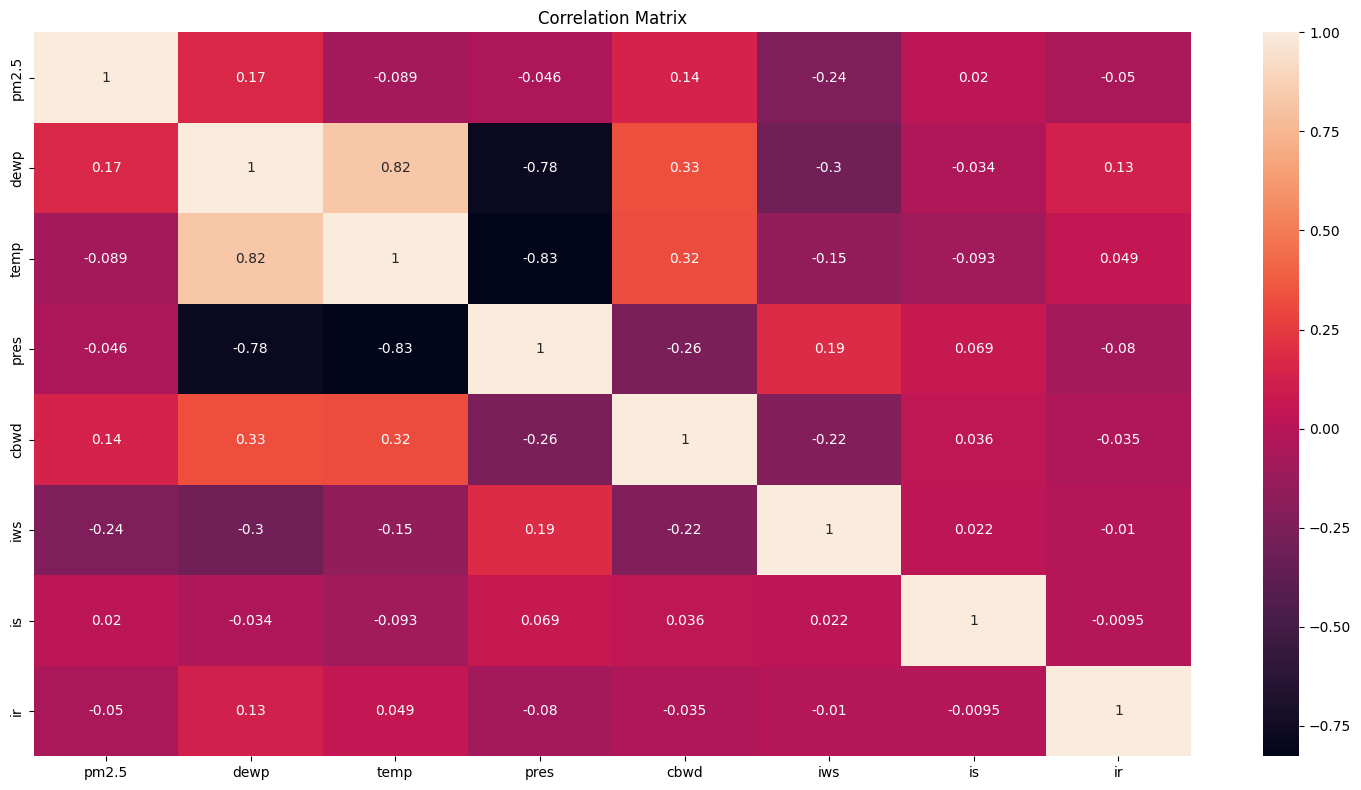

In [16]:
# Fill missing values with the median of each column before calculating correlation
sns.heatmap(df.fillna(df.median(numeric_only=True)).corr(), annot=True)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

## Feature Analysis

Text(0.5, 1.0, 'PM2.5')

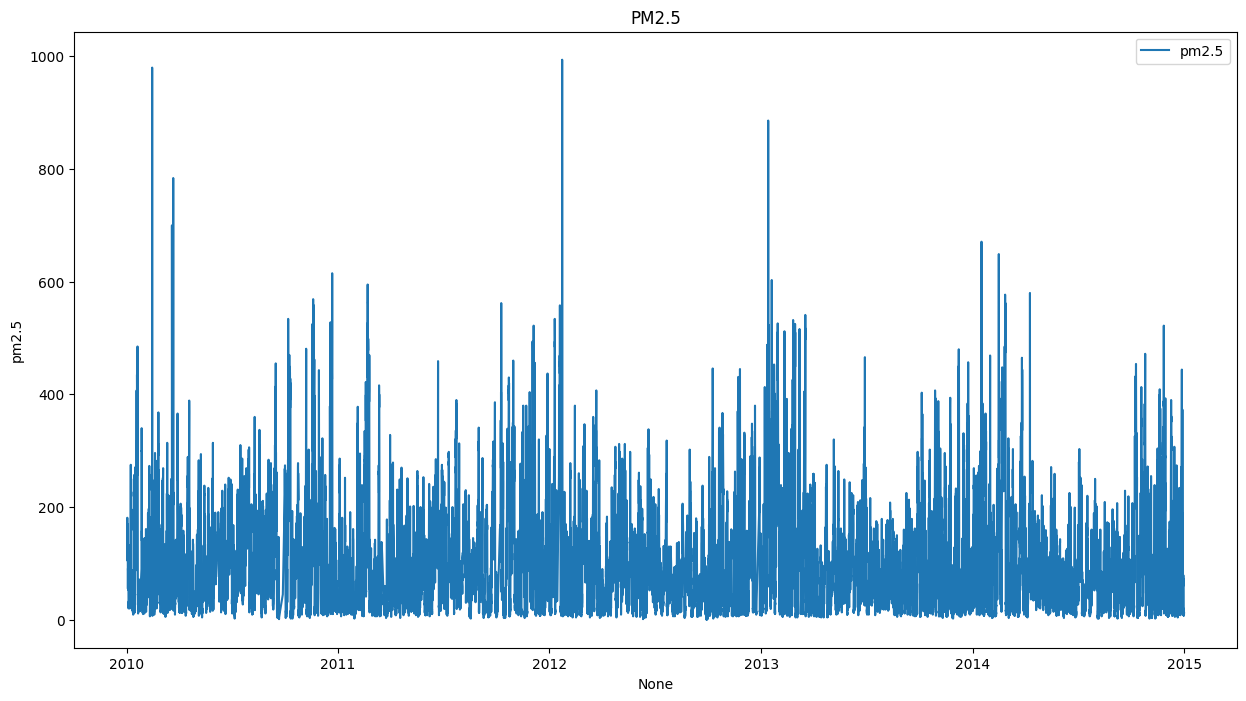

In [ ]:
sns.lineplot(data=df, x=df.index, y='pm2.5', label='pm2.5')
plt.title('PM2.5')

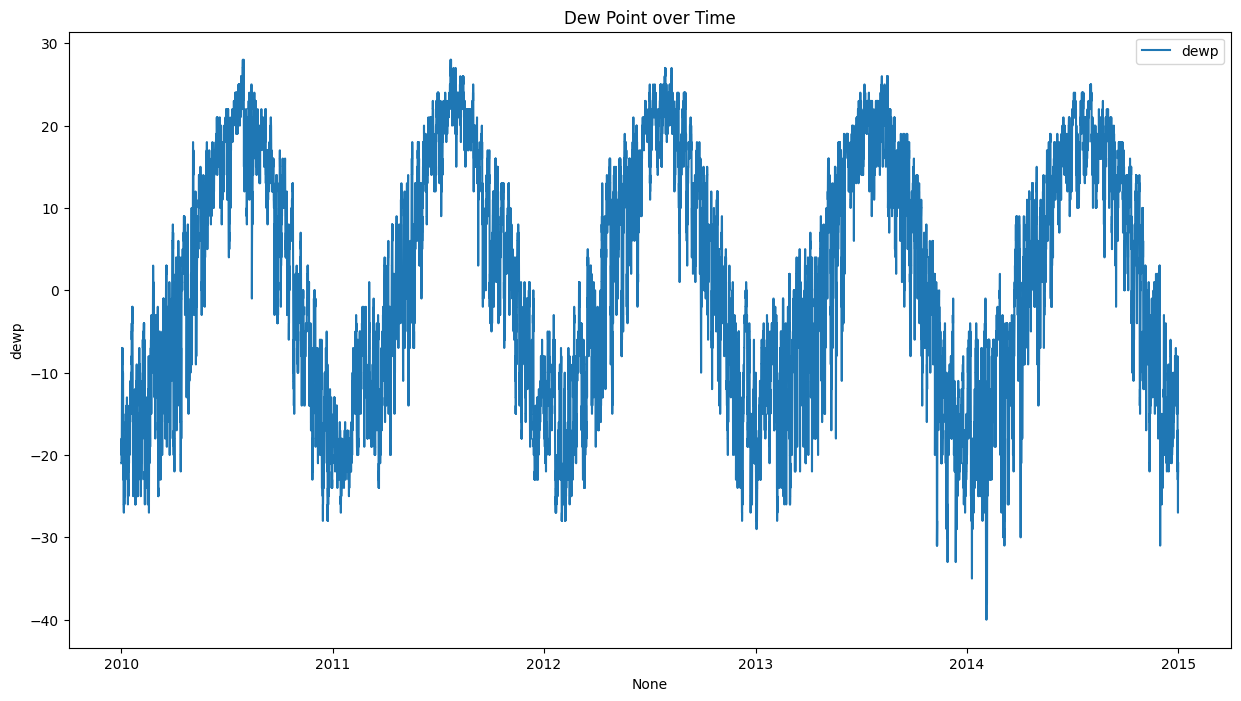

In [18]:
sns.lineplot(data=df, x=df.index, y='dewp', label='dewp')
plt.title('Dew Point over Time');

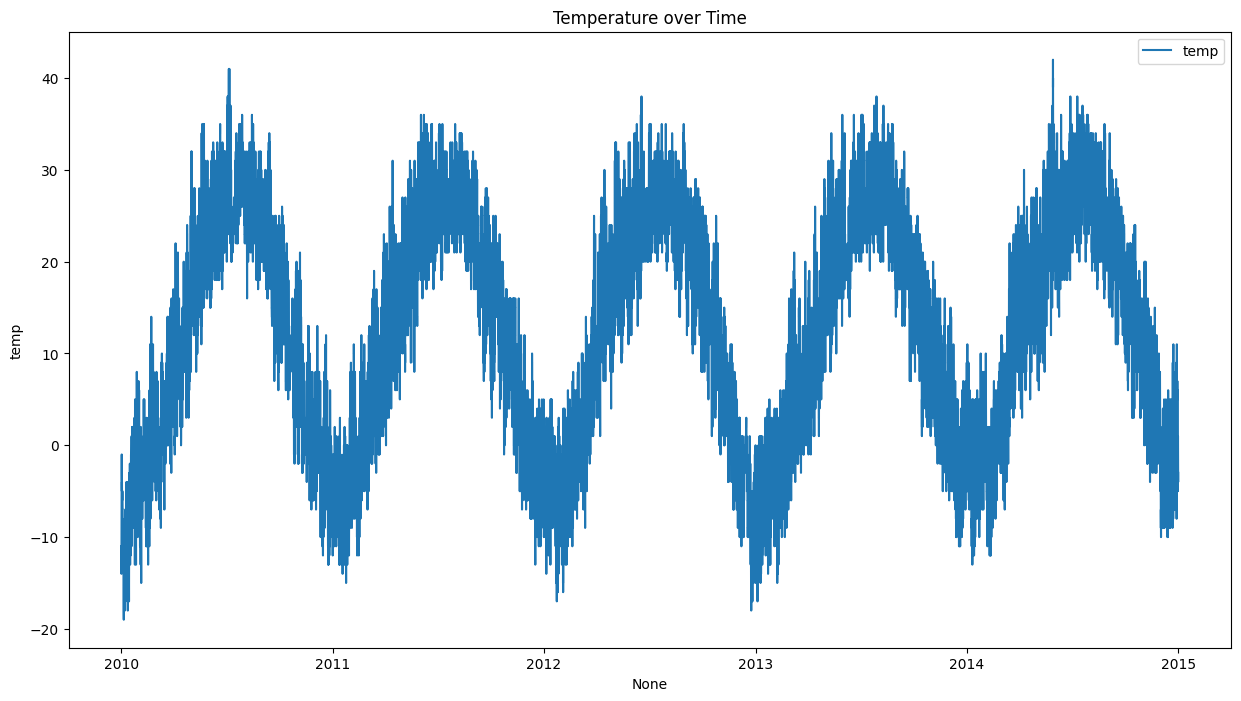

In [ ]:
sns.lineplot(data=df, x=df.index, y='temp', label='temp')
plt.title('Temperature over Time');

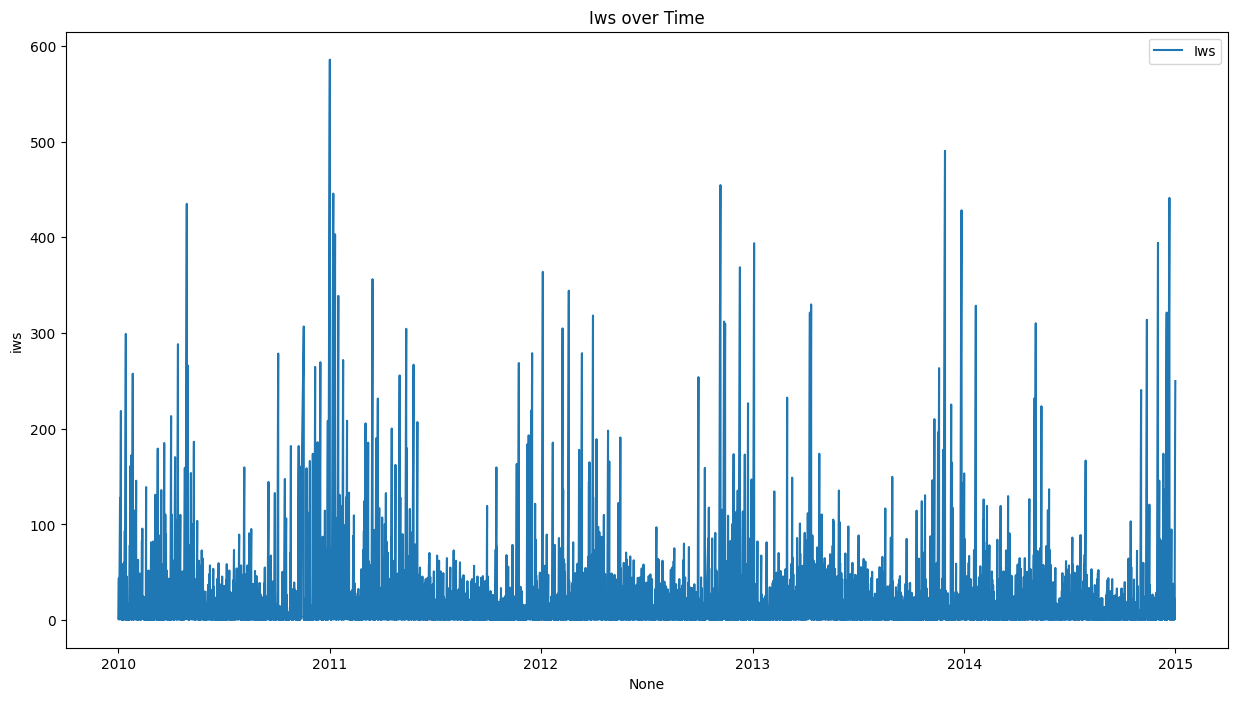

In [23]:
sns.lineplot(data=df, x=df.index, y='iws', label='Iws')
plt.title('Iws over Time');

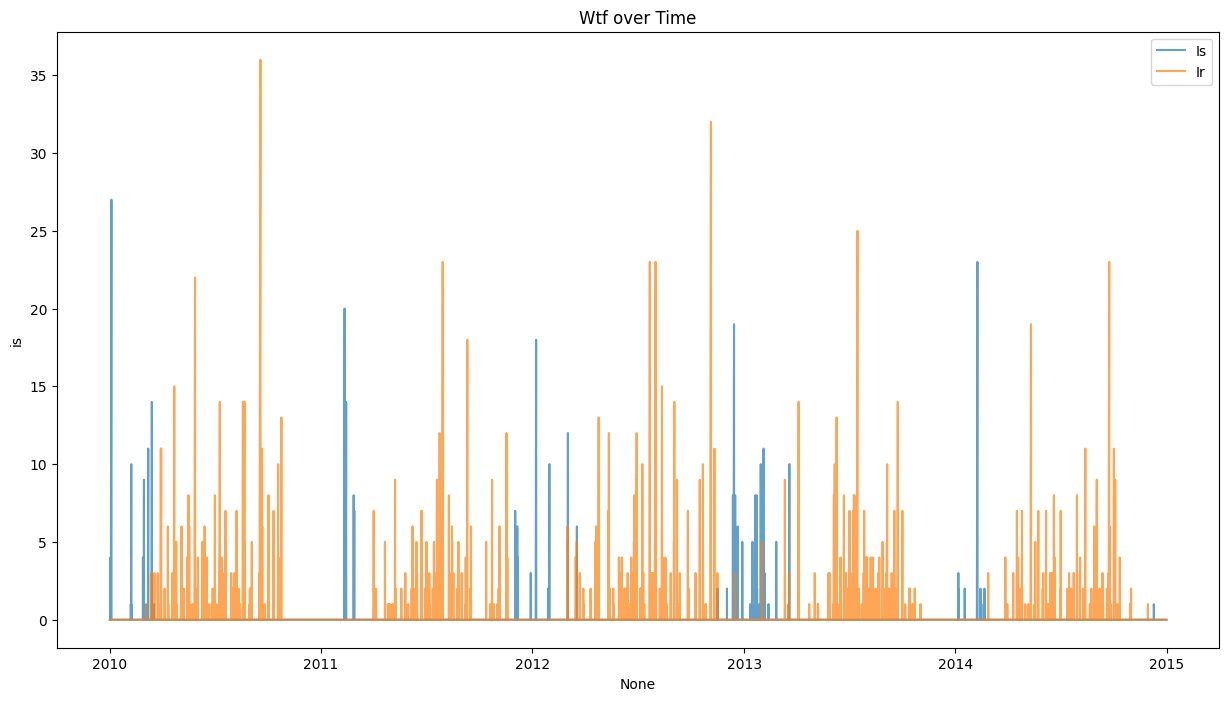

In [24]:
sns.lineplot(data=df, x=df.index, y='is', label='Is', alpha=0.7)
sns.lineplot(data=df, x=df.index, y='ir', label='Ir', alpha=0.7)
plt.title('Wtf over Time');
plt.legend();

## Peaks detection

In [25]:
from scipy.signal import find_peaks

def normalize_zscore(y):
    return (y - np.mean(y)) / np.std(y)

def robust_zscore(y):
    y = np.array(y)
    med = np.median(y)
    mad = np.median(np.abs(y - med))
    return (y - med) / (mad if mad > 1e-6 else 1)

def plot_spikes_and_drops(x, y, title="Signal with Spikes and Drops", prominence=1.0, robust=False):

    if robust:
        y_pred_norm = robust_zscore(y)
    else:
        y_pred_norm = normalize_zscore(y)
    peaks, _ = find_peaks(y_pred_norm, prominence=prominence)  # use normalized threshold
    drops, _ = find_peaks(-y_pred_norm, prominence=prominence)  # use normalized threshold

    plt.figure(figsize=(15, 9))
    plt.plot(x, y, label="Signal", color="gray")
    plt.plot(x[peaks], y[peaks], "r^", label="Spikes")
    plt.plot(x[drops], y[drops], "bv", label="Drops")
    plt.title(title)
    plt.xlabel("Time")
    plt.ylabel("Value")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_18076\555613157.py:23: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.plot(x[peaks], y[peaks], "r^", label="Spikes")
C:\Users\HP\AppData\Local\Temp\ipykernel_18076\555613157.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.plot(x[drops], y[drops], "bv", label="Drops")


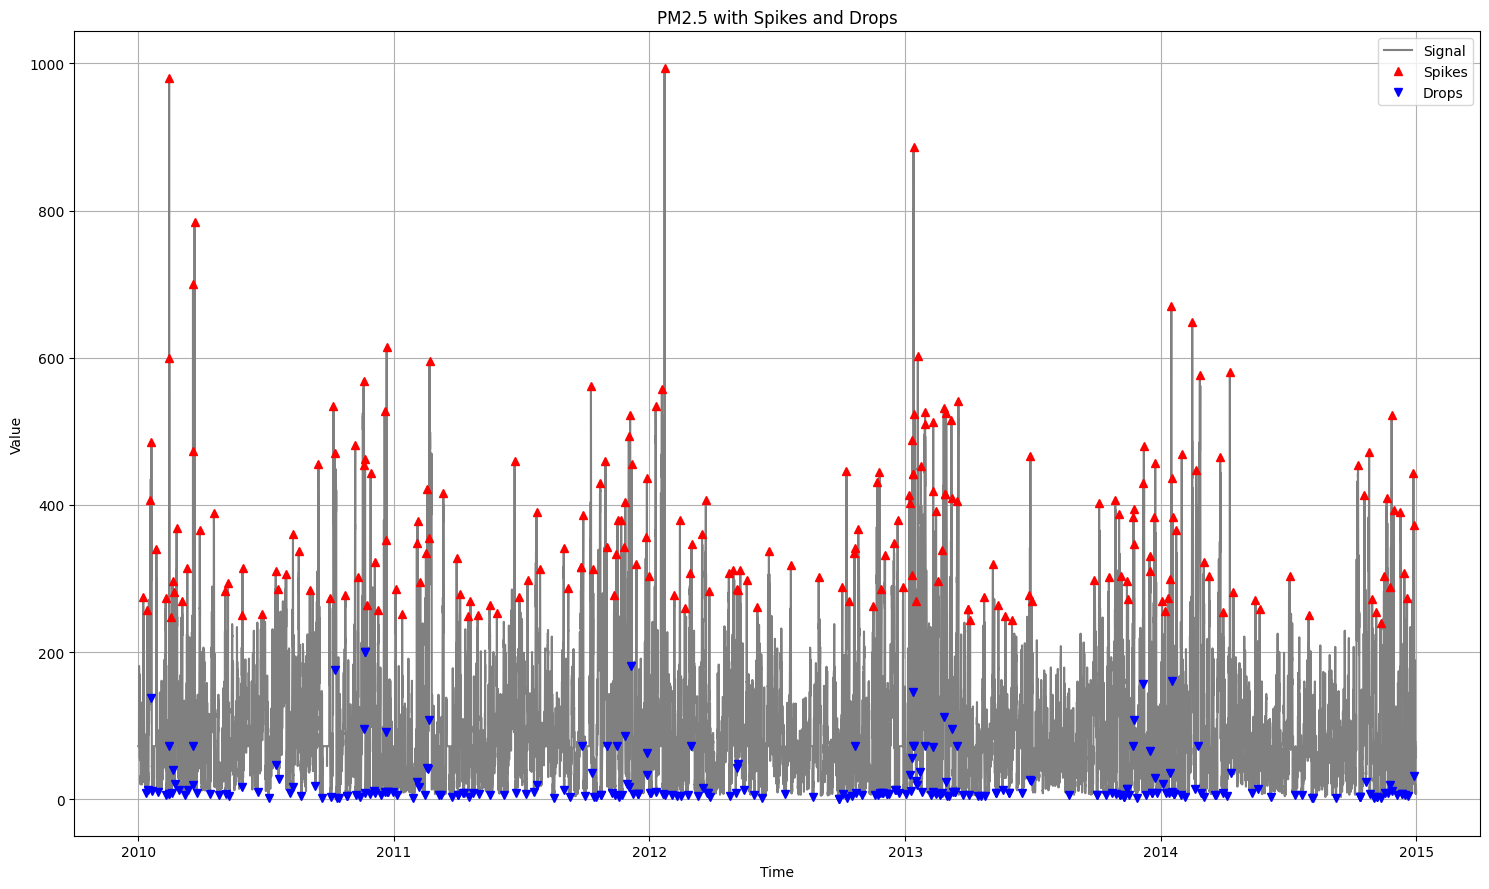

In [30]:
plot_spikes_and_drops(df.index,
                      df['pm2.5'].fillna(df['pm2.5'].median()), 
                      title="PM2.5 with Spikes and Drops",
                      prominence=5.0, robust=True)

## Hourly patterns (data is already hourly)

In [31]:
def plot_hourly_data(series, title, color='blue'):
    # Choose a sensible default value for missing data
    fill_value = series.median() if not pd.isna(series.median()) else -100
    
     
    sns.lineplot(series.fillna(fill_value), label=f'hourly {title}', color=color)
    
    # Mark missing values
    plt.scatter(
        x=series[series.isna()].index,
        y=[series.min()-0.01]*series[series.isna()].shape[0],
        color='red',
        marker='x',
        label='missing'
    )
    
    plt.title(f"Hourly {title}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [35]:
pm25_hour_endog = df['pm2.5'].resample('H').mean()

C:\Users\HP\AppData\Local\Temp\ipykernel_18076\1586261203.py:1: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  pm25_hour_endog = df['pm2.5'].resample('H').mean()


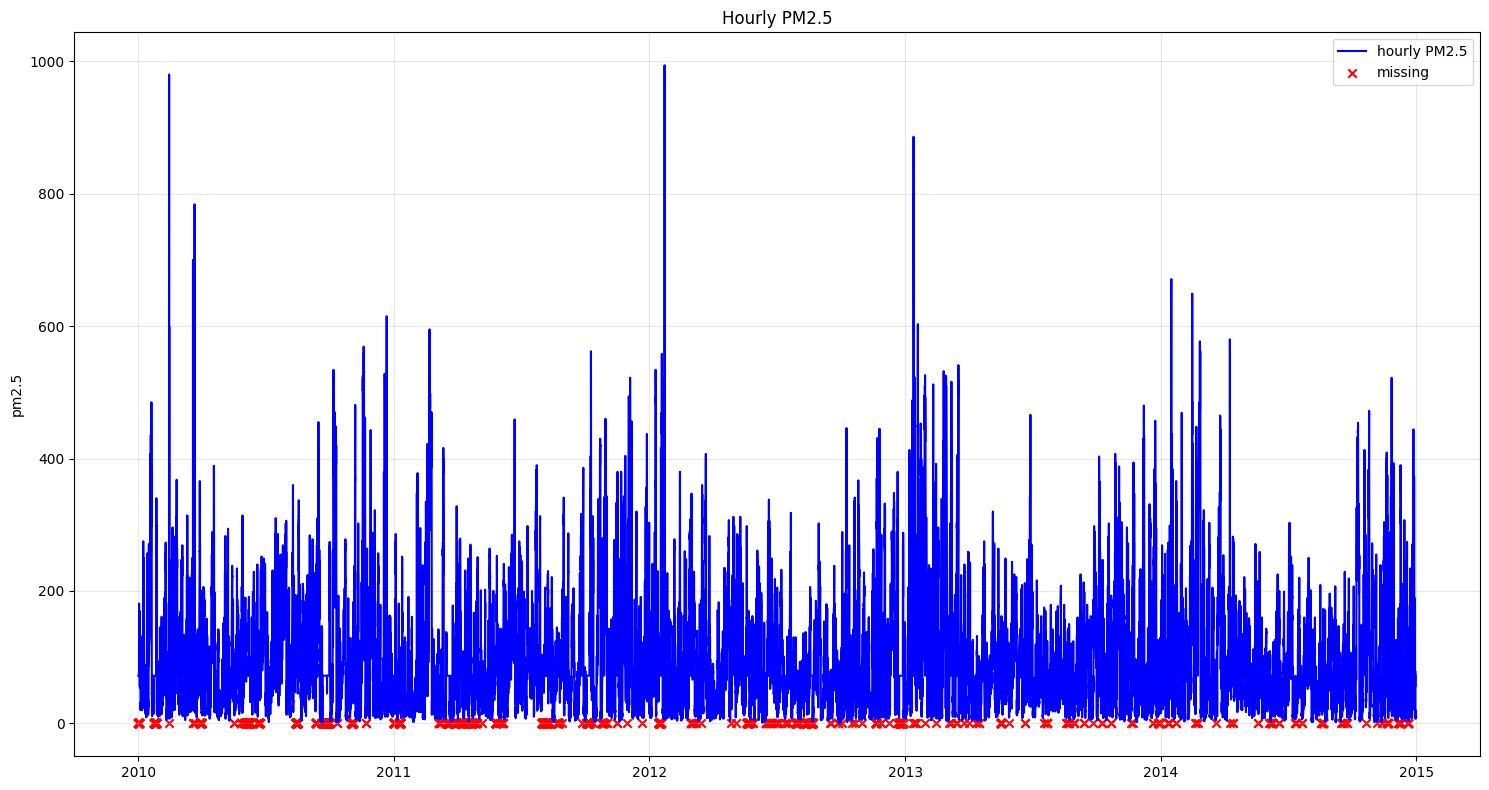

In [36]:
plot_hourly_data(pm25_hour_endog, 'PM2.5')

### Weekly Patterns Analysis (based on hourly analysis)

In [43]:
df.columns

Index(['pm2.5', 'dewp', 'temp', 'pres', 'cbwd', 'iws', 'is', 'ir',
       'day_of_week', 'hour'],
      dtype='object')

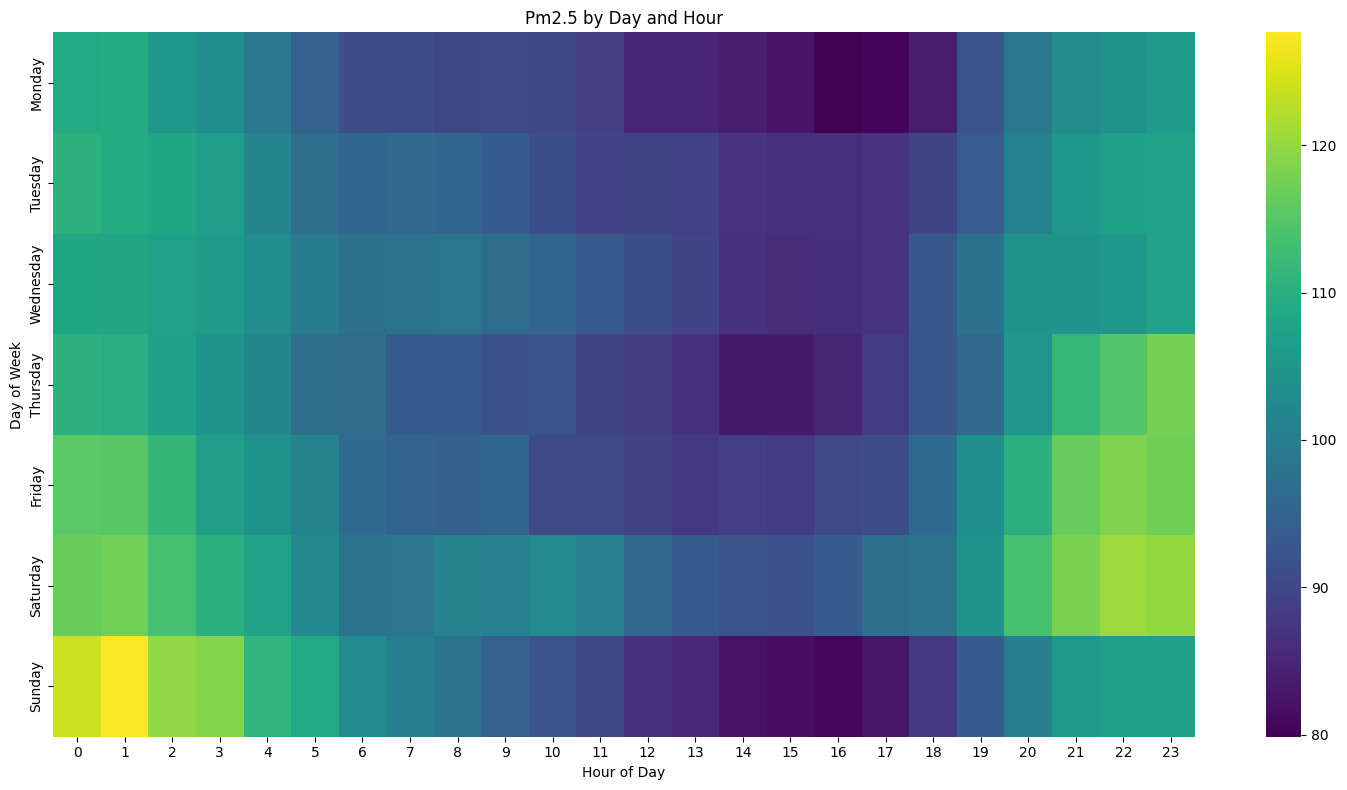

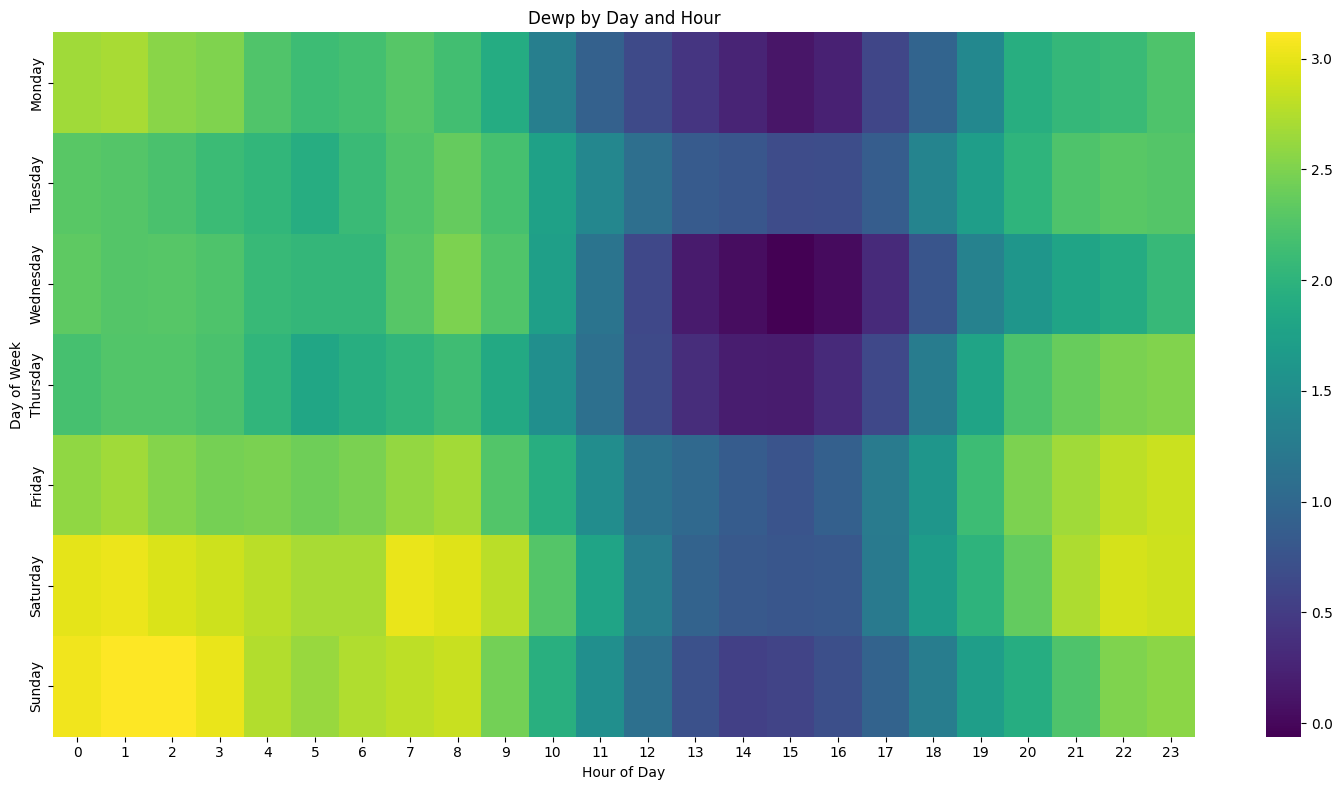

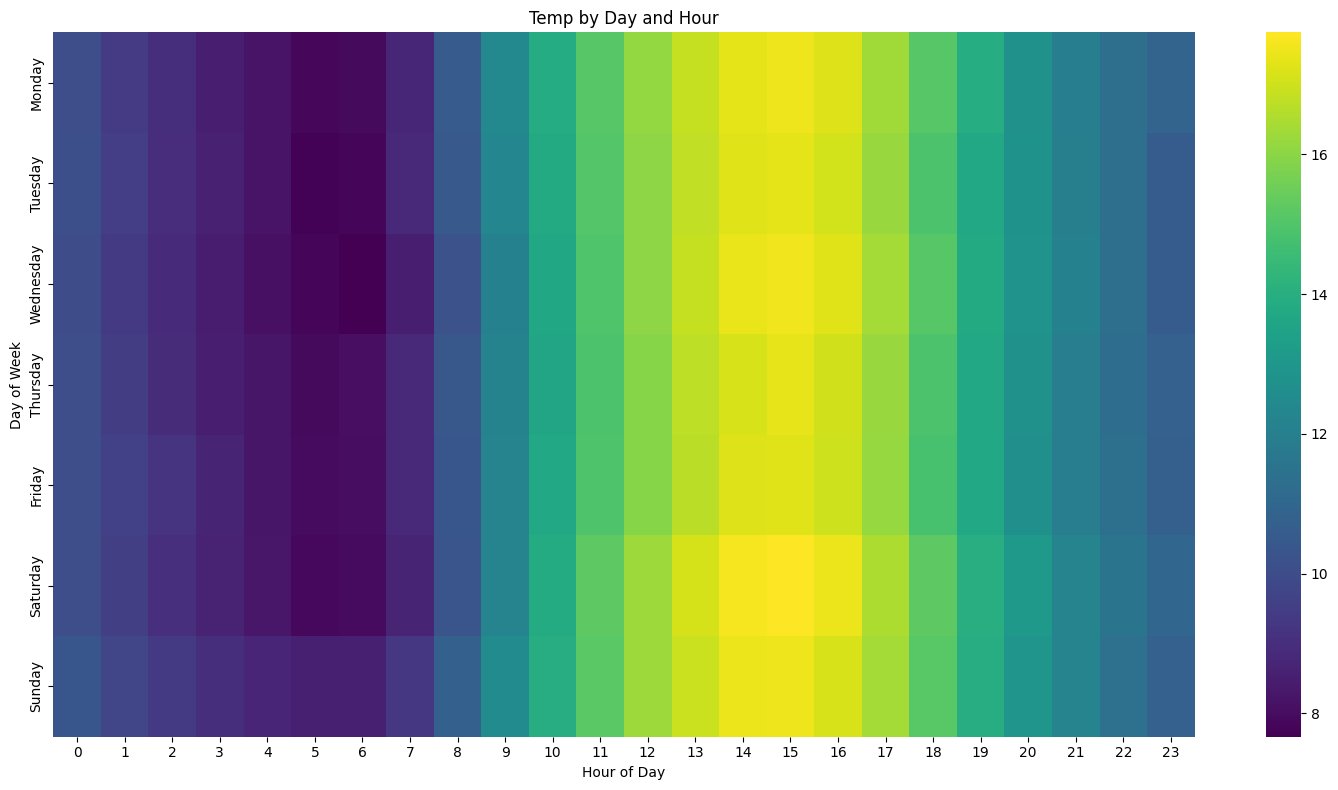

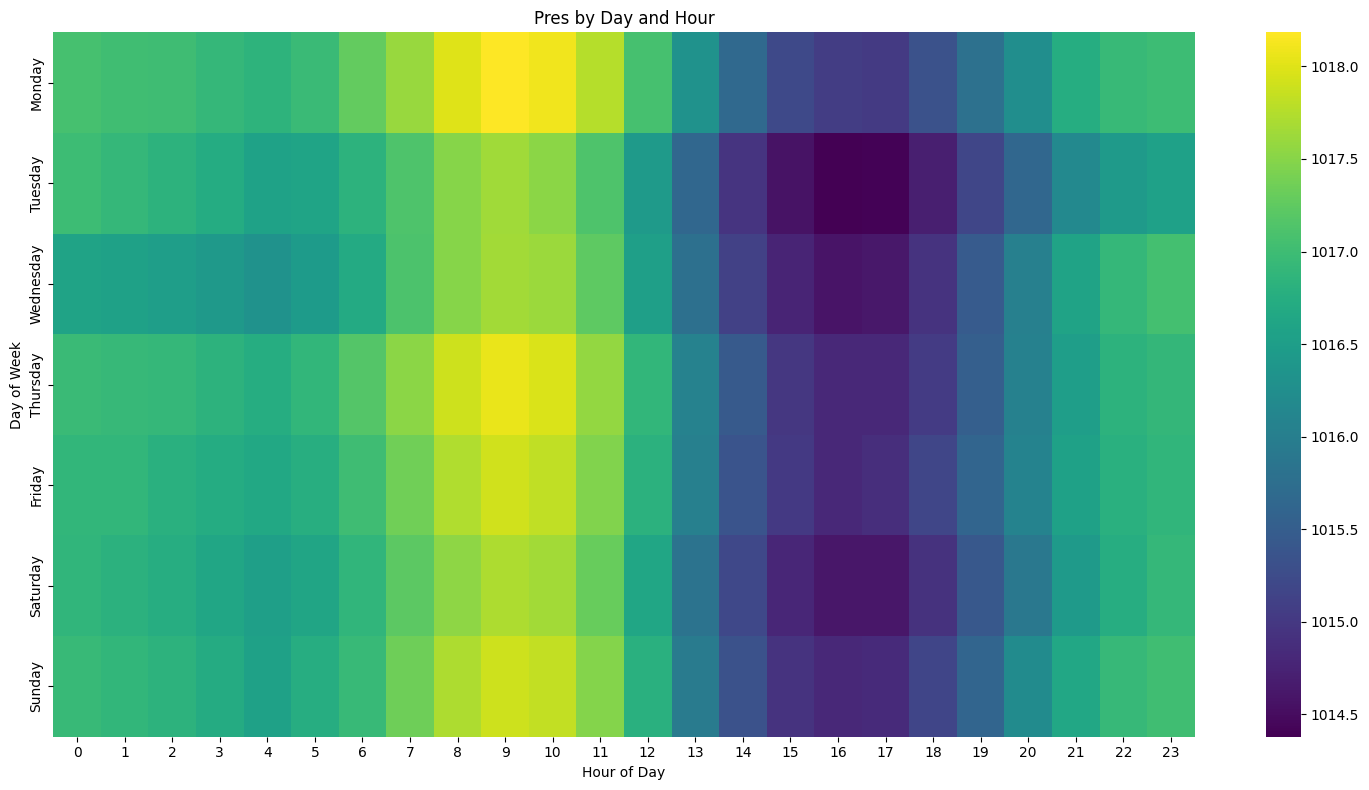

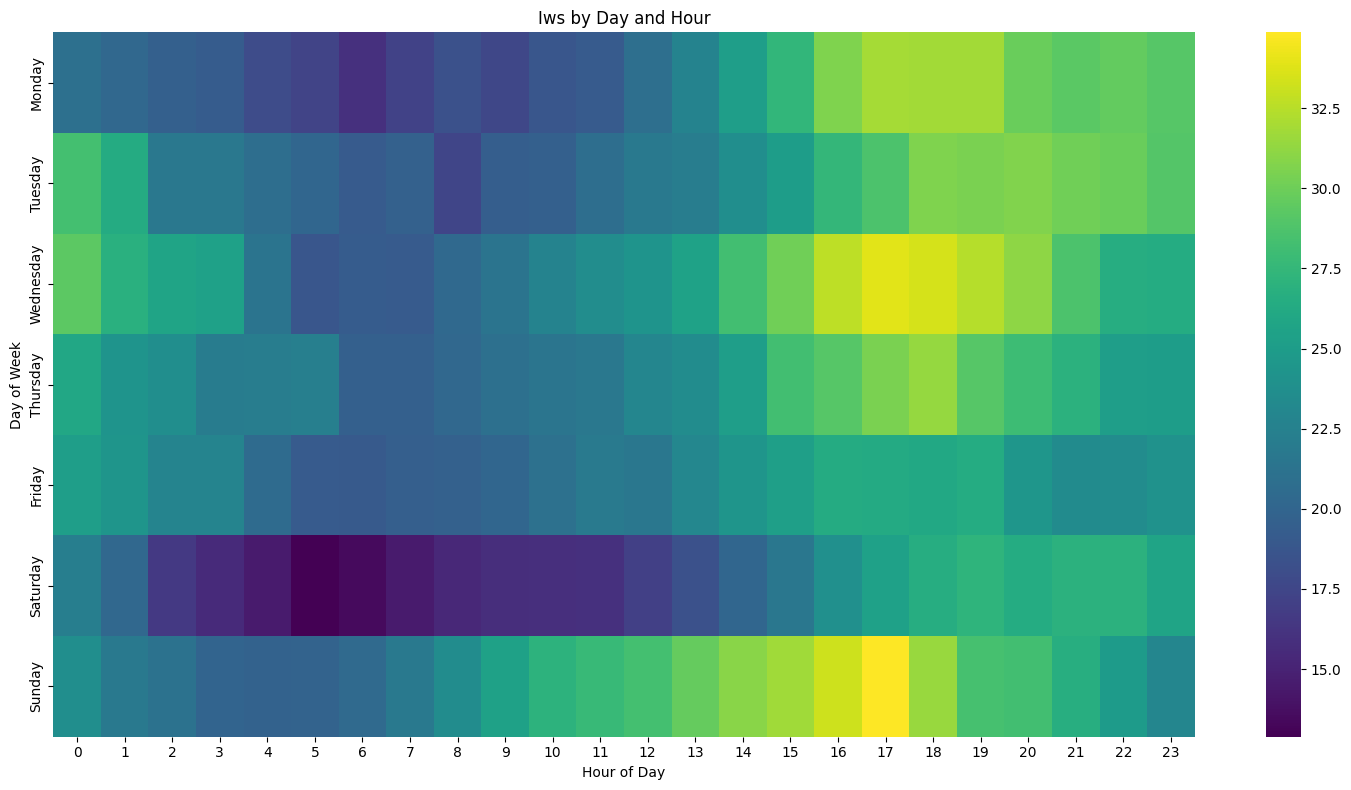

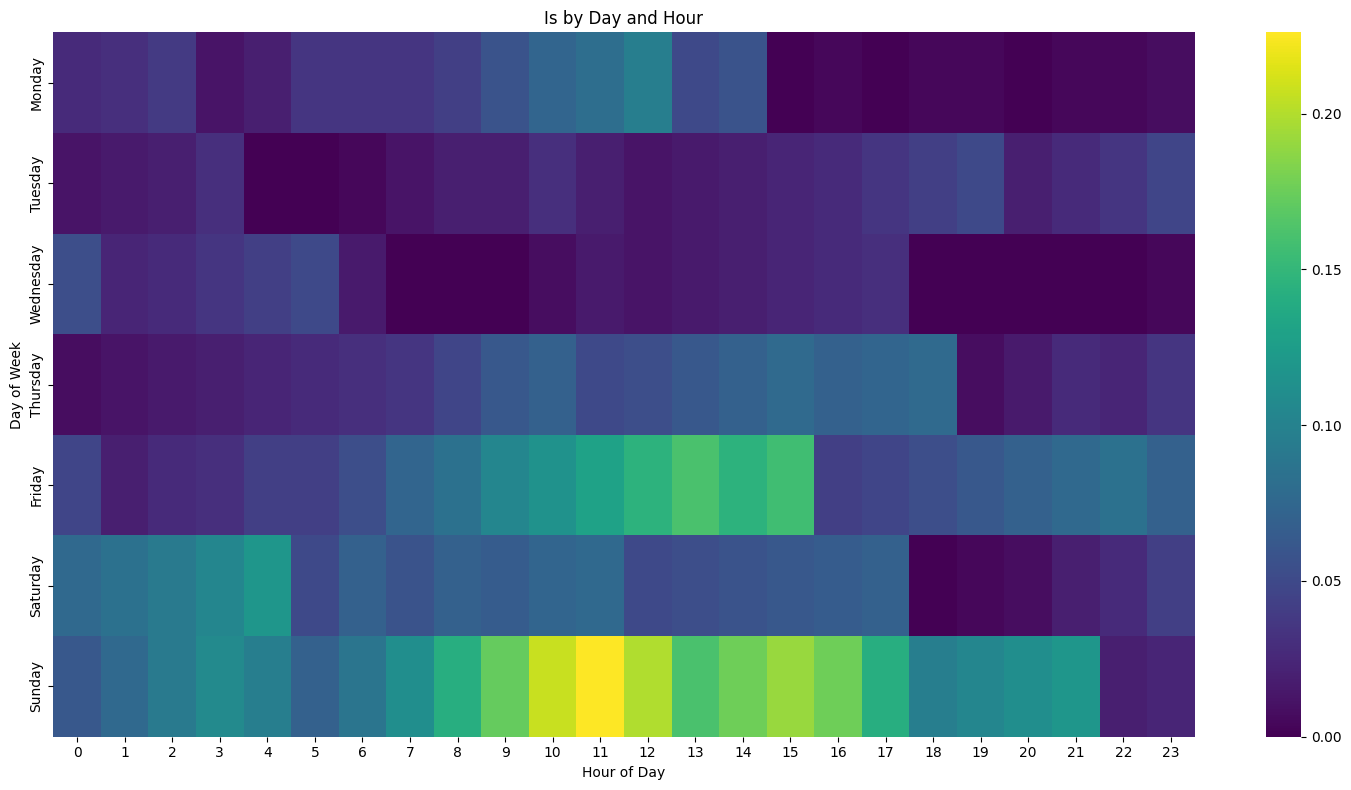

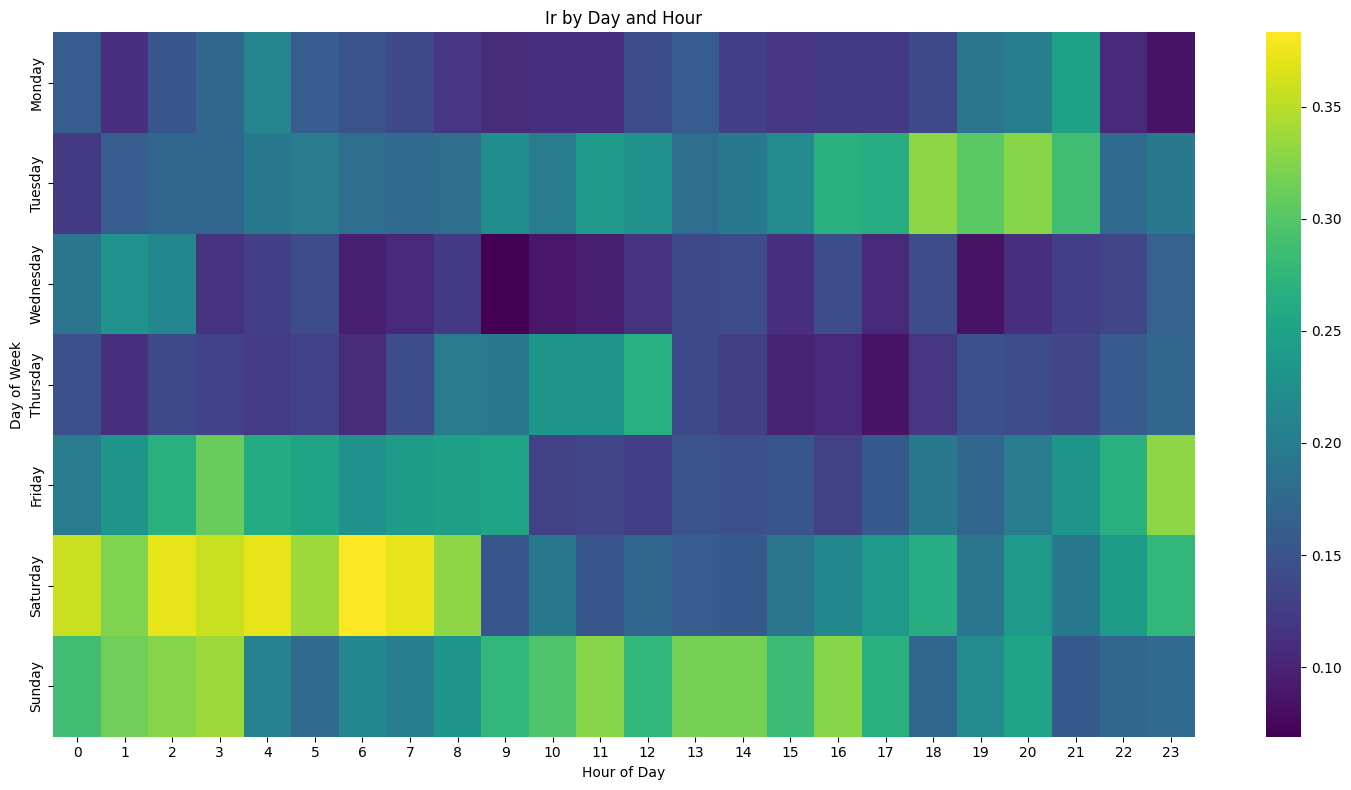

In [ ]:
# Extract day of week and hour
df['day_of_week'] = df.index.day_name()
df['hour'] = df.index.hour

# Group by day of week and hour
daily_patterns = df.groupby(['day_of_week', 'hour']).agg({
    'pm2.5': 'mean',
    'dewp': 'mean',
    'temp': 'mean',
    'pres': 'mean',
    'iws': 'mean',
    'is': 'mean',
    'ir': 'mean'
}).reset_index()

# Order days correctly
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daily_patterns['day_of_week'] = pd.Categorical(daily_patterns['day_of_week'], categories=day_order, ordered=True)
daily_patterns = daily_patterns.sort_values(['day_of_week', 'hour'])

# Plot heatmap for each column
for column in df.columns:
    if column in ['day_of_week', 'hour', 'cbwd']:
        continue
    pivot_table = daily_patterns.pivot(index='day_of_week', columns='hour', values=column)
    sns.heatmap(pivot_table, cmap='viridis', annot=False)
    plt.title(f'{column.replace("_", " ").title()} by Day and Hour')
    plt.xlabel('Hour of Day')
    plt.ylabel('Day of Week')
    plt.tight_layout()
    plt.show()

### Monthly Patterns Analysis

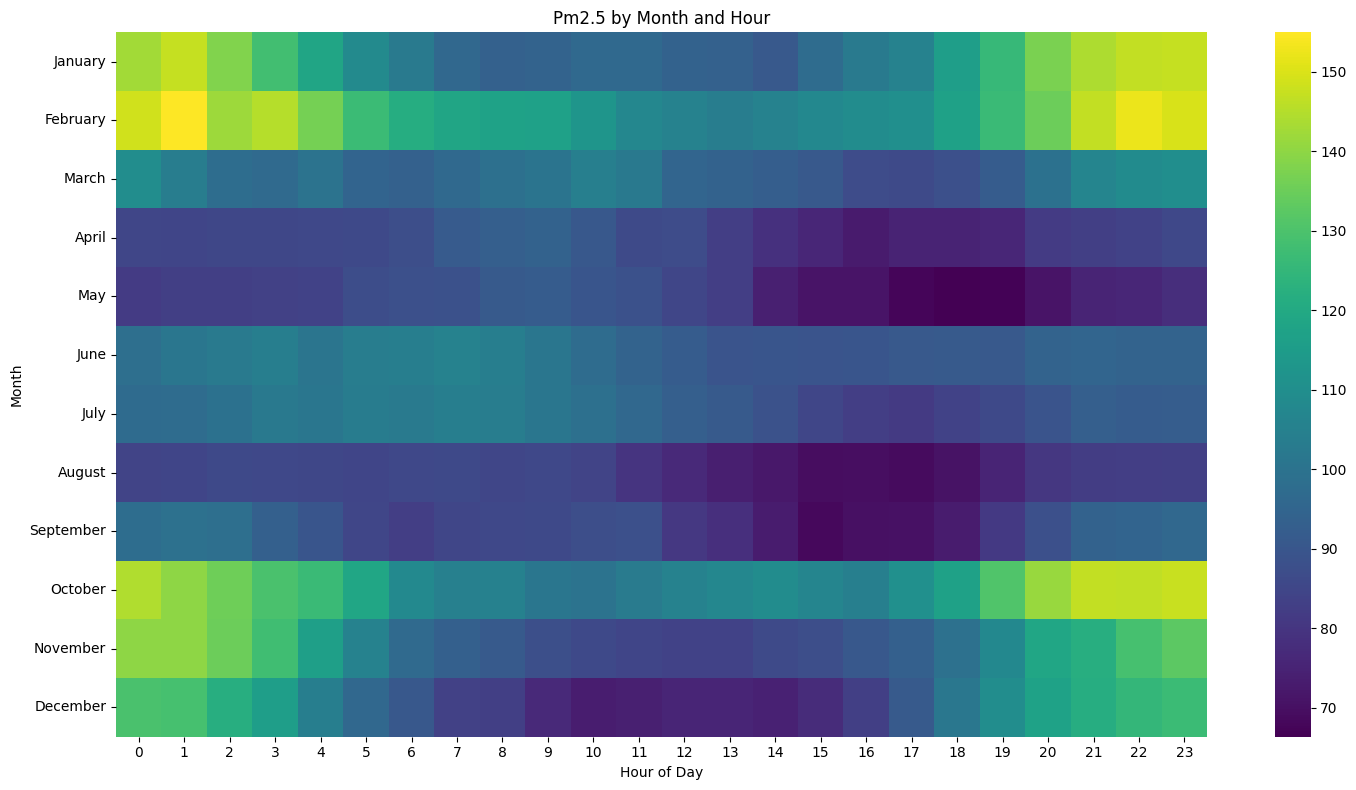

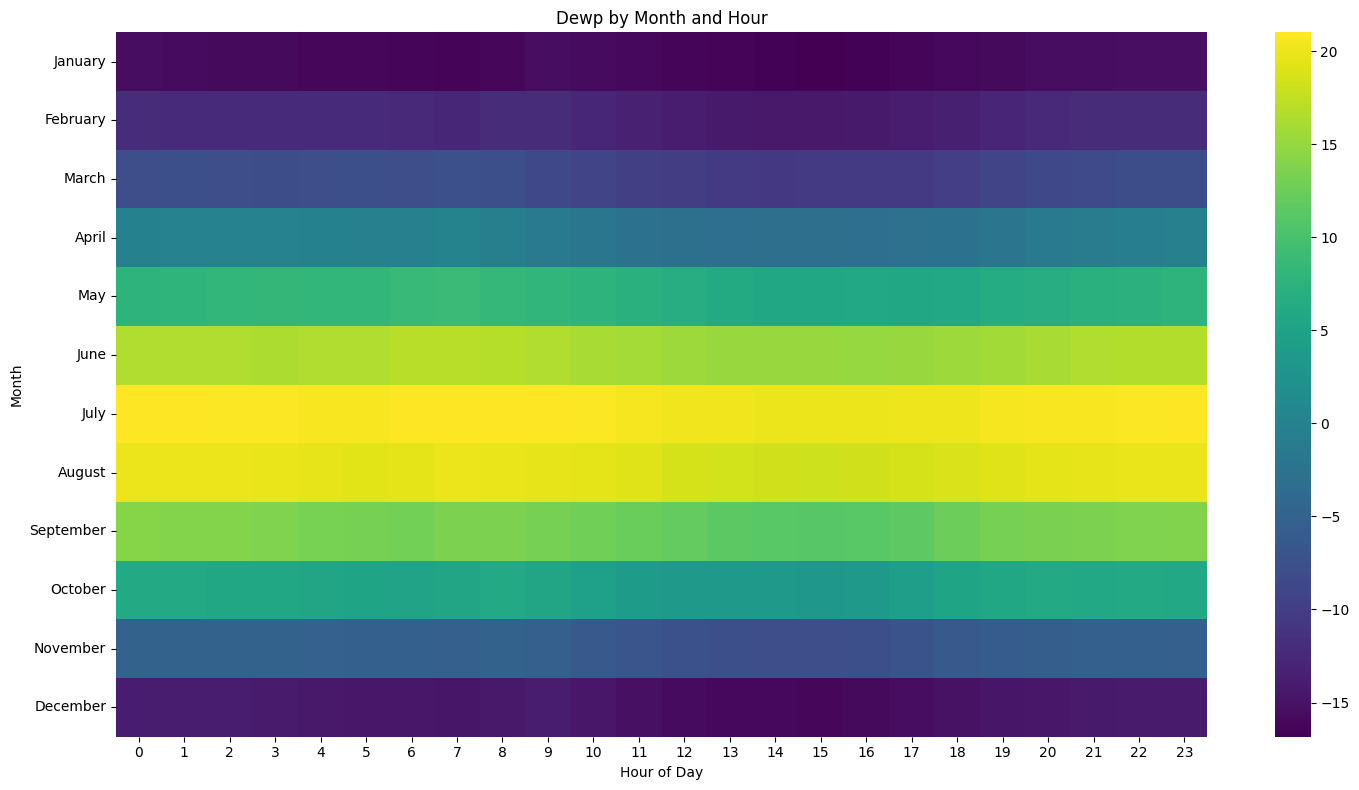

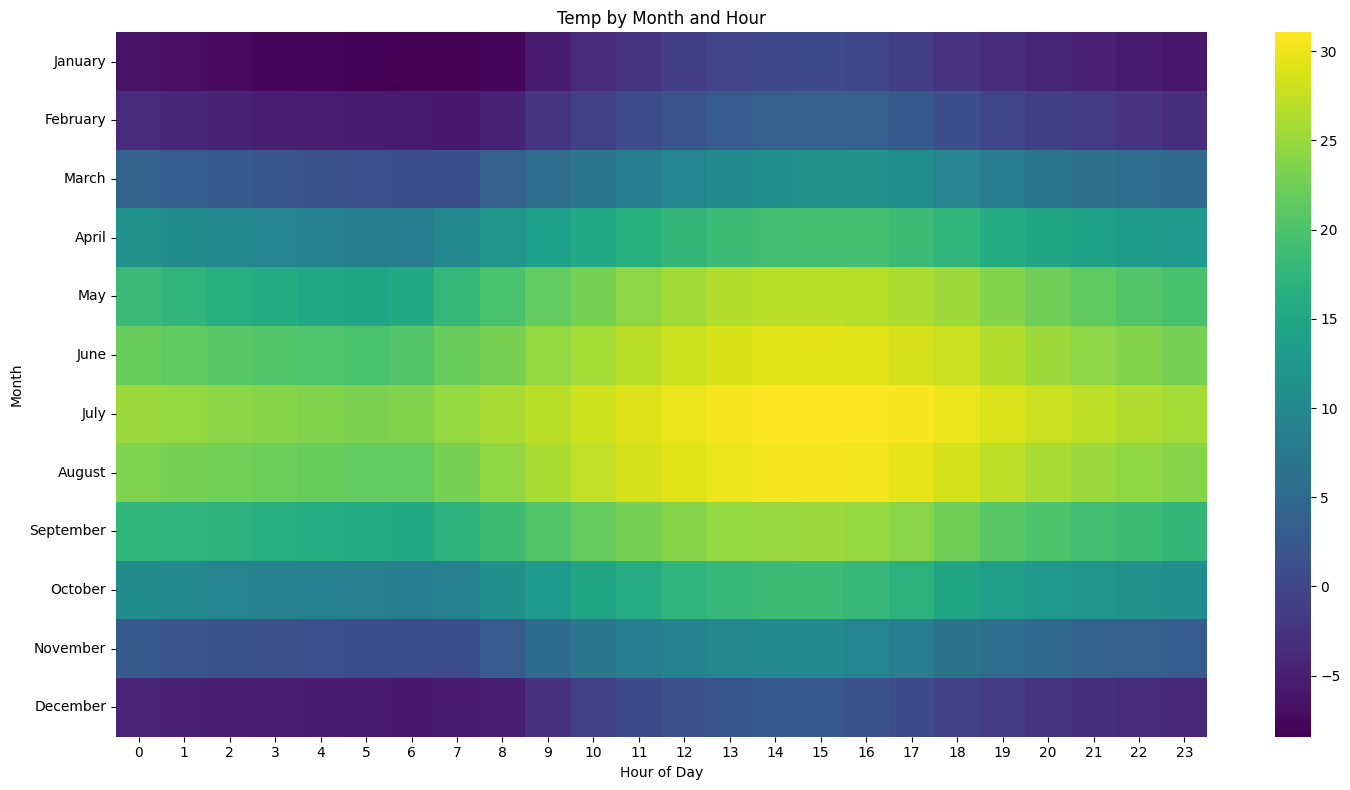

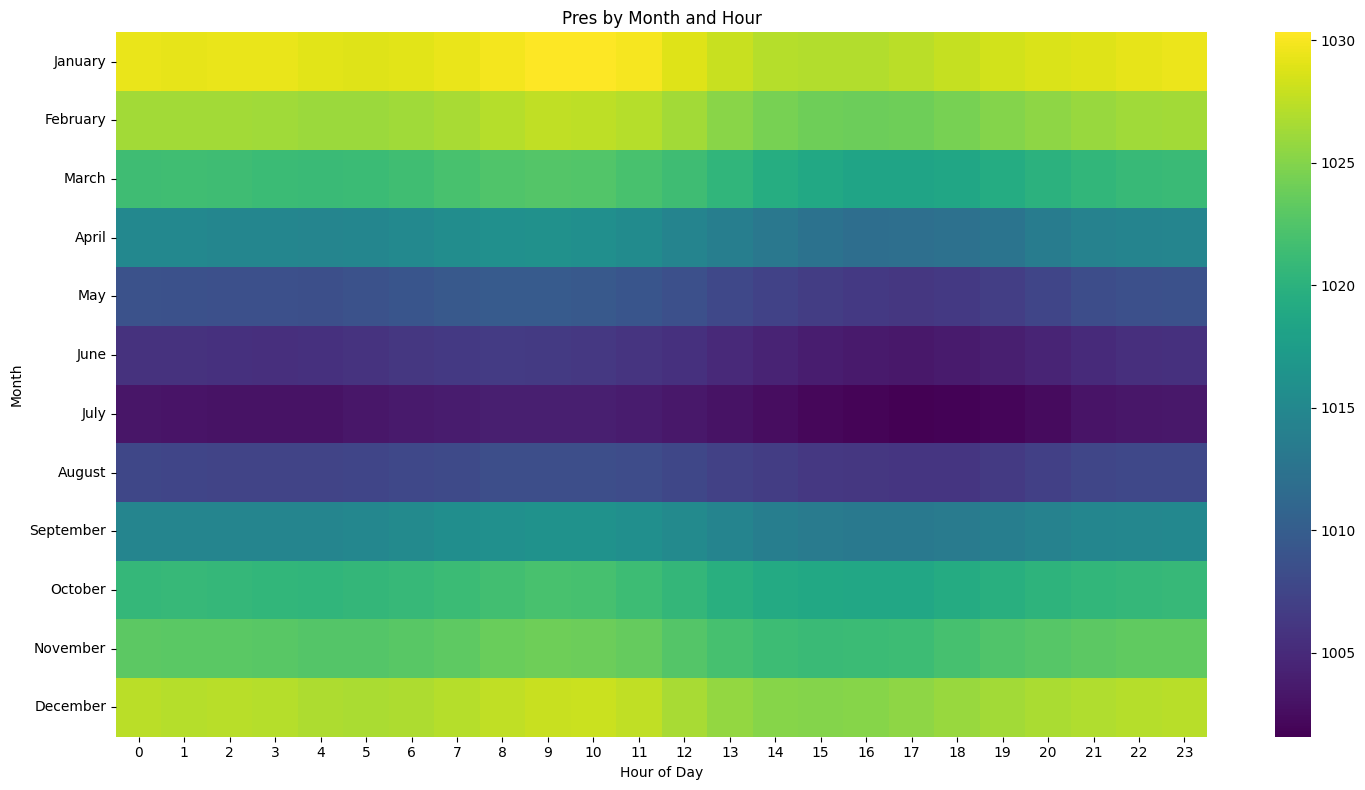

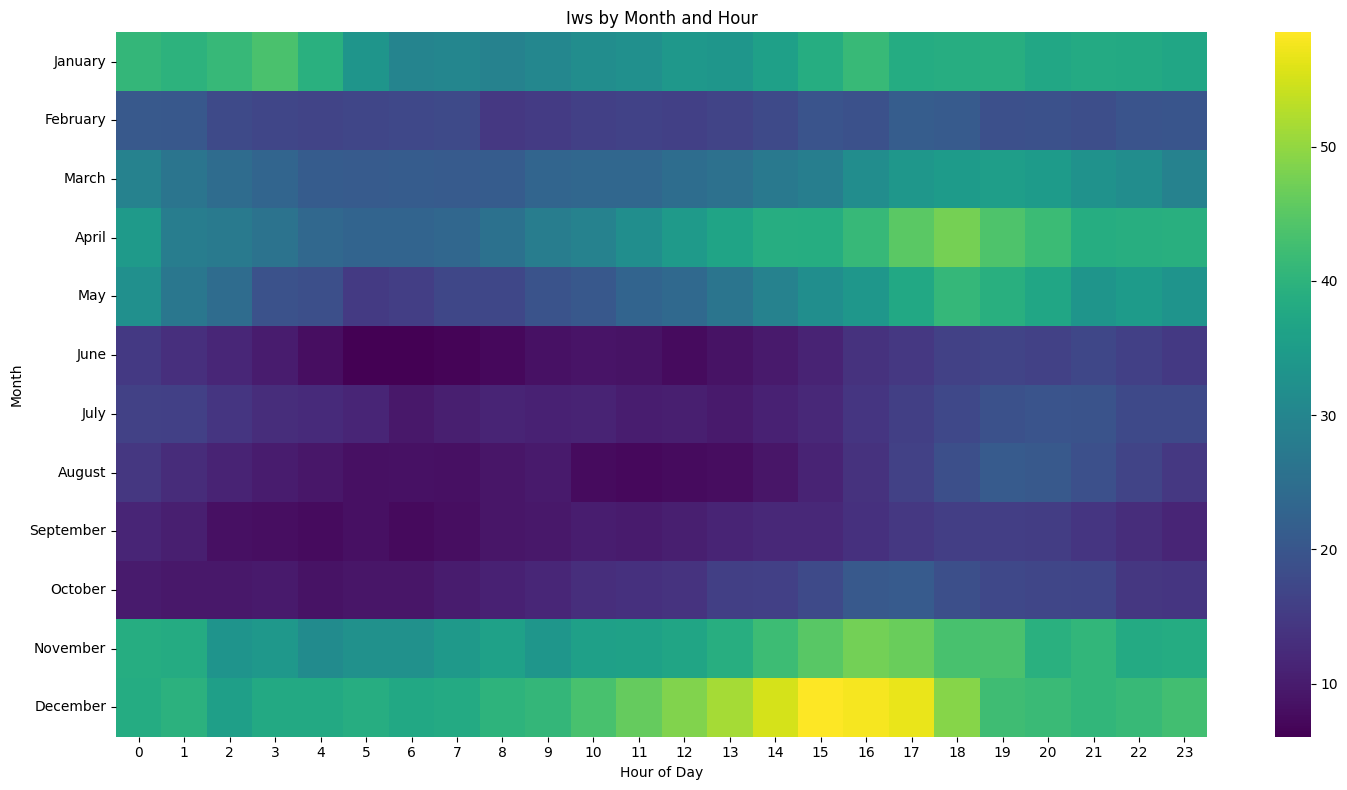

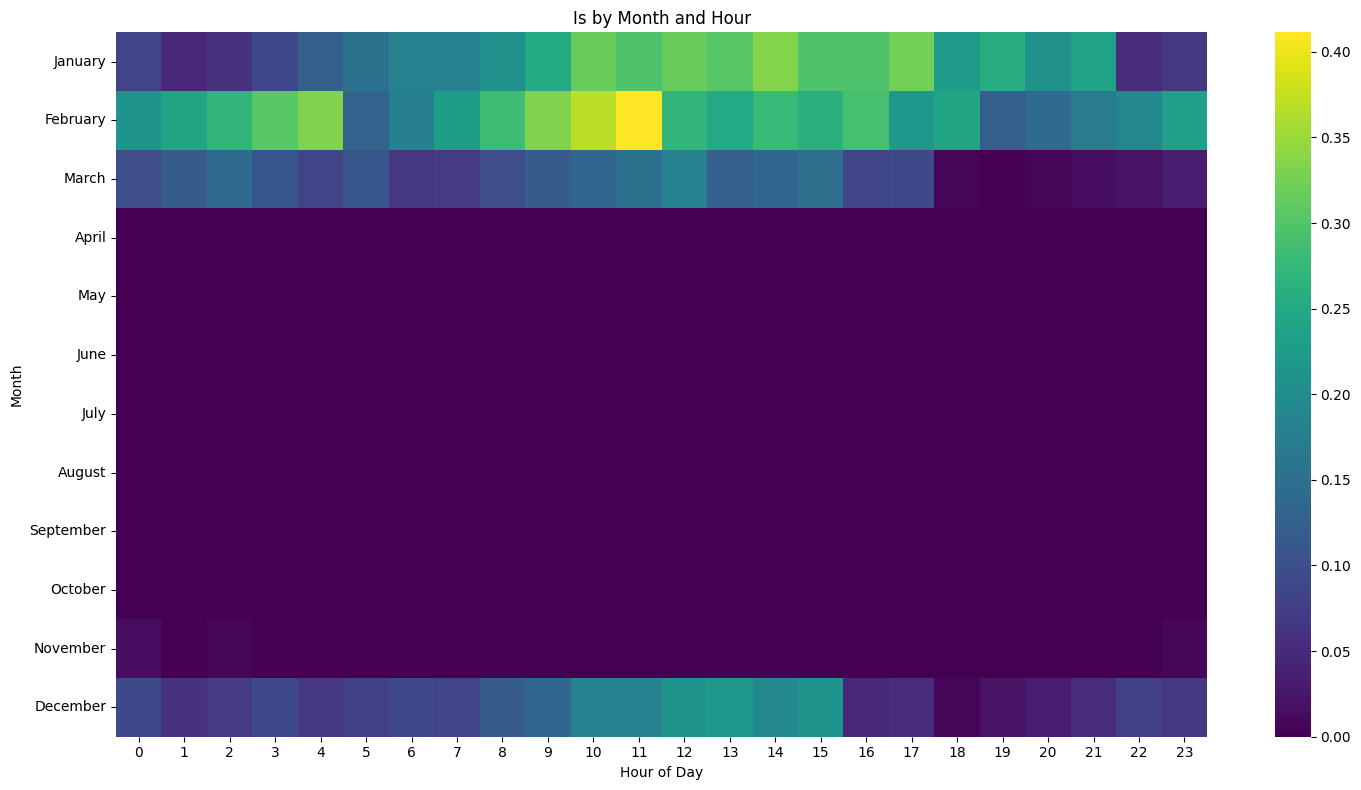

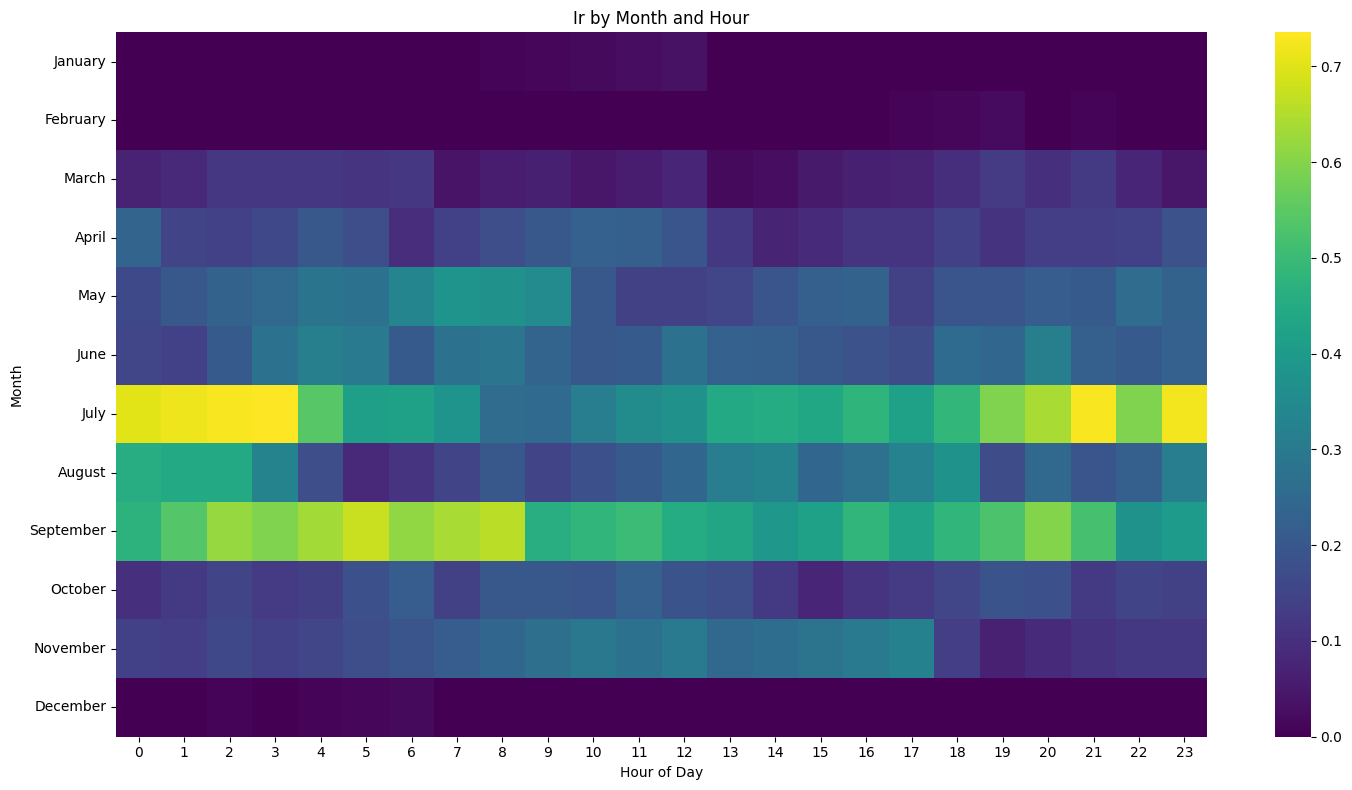

In [46]:
# Extract month and hour
df['month'] = df.index.month_name()
df['hour'] = df.index.hour

# Group by month and hour
monthly_patterns = df.groupby(['month', 'hour']).agg({
    'pm2.5': 'mean',
    'dewp': 'mean',
    'temp': 'mean',
    'pres': 'mean',
    'iws': 'mean',
    'is': 'mean',
    'ir': 'mean'
}).reset_index()

# Order months correctly
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']
monthly_patterns['month'] = pd.Categorical(monthly_patterns['month'], categories=month_order, ordered=True)
monthly_patterns = monthly_patterns.sort_values(['month', 'hour'])

# Plot heatmap for each column
for column in ['pm2.5', 'dewp', 'temp', 'pres', 'iws', 'is', 'ir']:
    pivot_table = monthly_patterns.pivot(index='month', columns='hour', values=column)
    sns.heatmap(pivot_table, cmap='viridis', annot=False)
    plt.title(f'{column.replace("_", " ").title()} by Month and Hour')
    plt.xlabel('Hour of Day')
    plt.ylabel('Month')
    plt.tight_layout()
    plt.show()


### Autocorrelation Analysis

#### Weekly

<Figure size 1500x600 with 0 Axes>

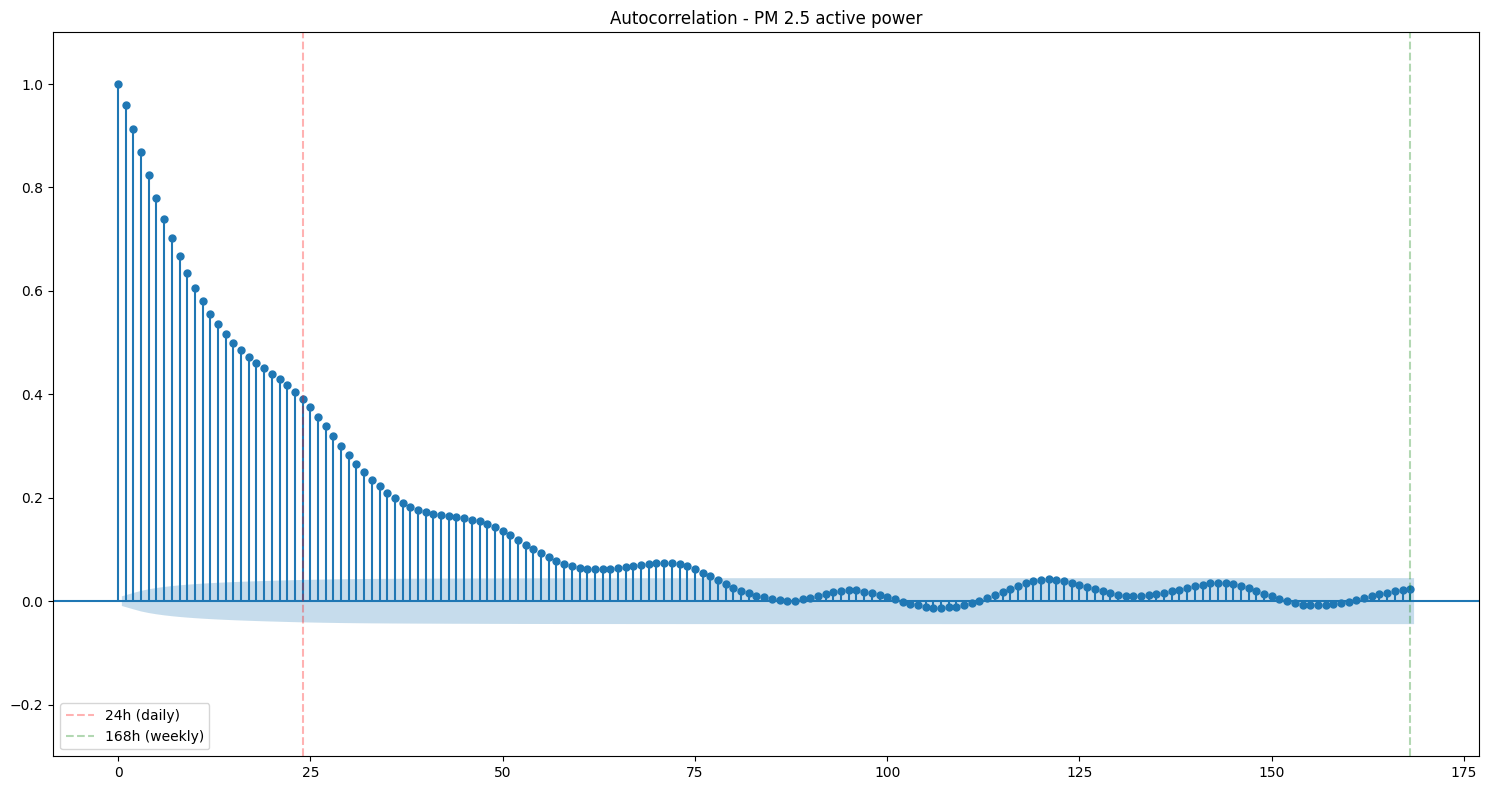

<Figure size 1500x600 with 0 Axes>

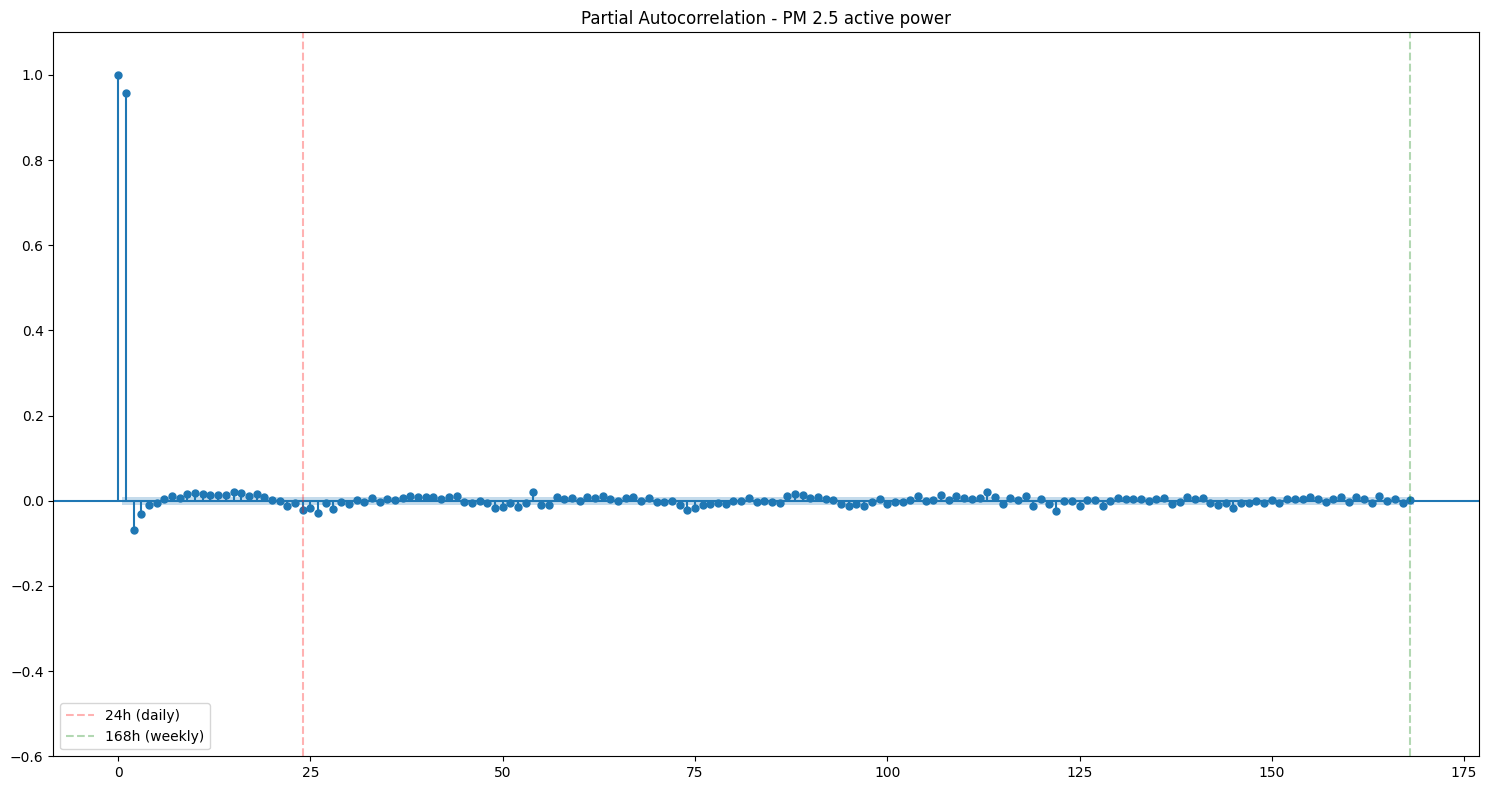

In [48]:
def plot_acf_pacf(series, lags, phase_label):
    fill_value = series.median() if not pd.isna(series.median()) else -100
    filled_series = series.fillna(fill_value)
    
    plt.figure(figsize=(15, 6))
    plot_acf(filled_series, lags=lags, title=f'Autocorrelation - {phase_label} active power')
    plt.ylim(-0.3, 1.1)
    plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(15, 6))
    plot_pacf(filled_series, lags=lags, title=f'Partial Autocorrelation - {phase_label} active power')
    plt.ylim(-0.6, 1.1)
    plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_acf_pacf(pm25_hour_endog, lags=24*7, phase_label='PM 2.5')